# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [1]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [3]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі ПІСЛЯ, викликаючи `set_seed()`. Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [4]:
numbers = list(range(10))  # список для shuffle

# TODO: двічі ДО set_seed() -- наприклад random.randint(1, 100) і random.shuffle(numbers)
rand_numbers = [random.randint(1, 100) for _ in range(10)]
print('random.randint() numbers one: ', rand_numbers)
rand_numbers = [random.randint(1, 100) for _ in range(10)]
print('random.randint() numbers two: ', rand_numbers)

num_copy = numbers.copy()

random.shuffle(numbers)
print('random.shuffle() numbers one: ', numbers)
random.shuffle(num_copy)
print('random.shuffle() numbers two: ', num_copy)
print()

set_seed()
print("Seed зафіксовано:", SEED)

# TODO: тепер двічі ПІСЛЯ set_seed() -- виклич set_seed() перед КОЖНИМ
# окремим генеруванням, не один раз на обидва
rand_numbers = [random.randint(1, 100) for _ in range(10)]
print('random.randint() numbers one: ', rand_numbers)

set_seed()
print("Seed зафіксовано:", SEED)
rand_numbers = [random.randint(1, 100) for _ in range(10)]
print('random.randint() numbers two: ', rand_numbers)
print()

numbers = list(range(10))
num_copy = numbers.copy()

set_seed()
print("Seed зафіксовано:", SEED)
random.shuffle(numbers)
print('random.shuffle() numbers one: ', numbers)

set_seed()
print("Seed зафіксовано:", SEED)
random.shuffle(num_copy)
print('random.shuffle() numbers two: ', num_copy)


random.randint() numbers one:  [98, 15, 97, 22, 13, 3, 13, 85, 22, 75]
random.randint() numbers two:  [90, 74, 40, 84, 98, 1, 55, 93, 94, 54]
random.shuffle() numbers one:  [2, 0, 6, 7, 4, 8, 5, 9, 1, 3]
random.shuffle() numbers two:  [3, 2, 5, 6, 1, 9, 0, 8, 4, 7]

Seed зафіксовано: 42
random.randint() numbers one:  [82, 15, 4, 95, 36, 32, 29, 18, 95, 14]
Seed зафіксовано: 42
random.randint() numbers two:  [82, 15, 4, 95, 36, 32, 29, 18, 95, 14]

Seed зафіксовано: 42
random.shuffle() numbers one:  [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Seed зафіксовано: 42
random.shuffle() numbers two:  [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]


Алгоритми псевдогенерації потребують певний сід (seed) для своєї роботи. До того, як ми викликали set_seed(), модулем random використовувався випадковий сід (наприклад на основі часу). Відповідно результат був новим при кожному виклику. Після ручного встановлення сіда генерація почала повертати одні і ті самі значення, оскільки ці алгоритми є матемтаично детермінованими.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [5]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [6]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [7]:
# TODO: zeros_arr = np.zeros((3, 4))
# TODO: sevens_arr = np.full((3, 4), 7)
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [8]:
# TODO: arange_arr = np.arange(0, 20, 2)
# TODO: linspace_arr = np.linspace(0, 1, 5)
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)


[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [9]:
# TODO: identity = np.eye(4)
# TODO: random_ints = np.random.randint(0, 10, size=(3, 3))
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity)
print('Dimentions: ', identity.ndim)
print(random_ints)
print('Dimentions: ', random_ints.ndim)


[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Dimentions:  2
[[6 3 7]
 [4 6 9]
 [2 6 7]]
Dimentions:  2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [10]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# TODO: порахувати mean, std і z_scores = (scores - mean) / std
mean = scores.mean()
std = scores.std()
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [11]:
arr = np.arange(1, 13)

# TODO: перетворити arr на матрицю 3x4 (reshape), порахувати суми по рядках
# (axis=1) і по стовпцях (axis=0)
matrix = arr.reshape((3,4))
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [12]:
df = pd.DataFrame({
    'name': ['Олена', 'Максим', 'Анна', 'Дмитро', 'Вікторія', 'Іван'],
    'score': [75, 92, 85, 60, 95, 81]
})

# TODO: відфільтрувати score > 80 і відсортувати за score за спаданням
top = df[df['score'] > 80].sort_values(by='score', ascending=False)
print(top)


       name  score
4  Вікторія     95
1    Максим     92
2      Анна     85
5      Іван     81


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [13]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
df["grade"] = df['score'].apply(lambda x: 'A' if x >= 90 else ('B' if x >= 75 else 'C'))
print(df)


       name  score grade
0     Олена     75     B
1    Максим     92     A
2      Анна     85     B
3    Дмитро     60     C
4  Вікторія     95     A
5      Іван     81     B


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [14]:
# TODO: zeros_t = torch.zeros((2, 3))
# TODO: sevens_t = torch.full((2, 3), 7)
zeros_t = torch.zeros((2,3))
sevens_t = torch.full((2,3), 7)

print(zeros_t)
print('zeros_t shape: ', zeros_t.shape)
print('zeros_t dtype: ', zeros_t.dtype)
print(sevens_t)
print('sevens_t shape: ', sevens_t.shape)
print('sevens_t dtype: ', sevens_t.dtype)


tensor([[0., 0., 0.],
        [0., 0., 0.]])
zeros_t shape:  torch.Size([2, 3])
zeros_t dtype:  torch.float32
tensor([[7, 7, 7],
        [7, 7, 7]])
sevens_t shape:  torch.Size([2, 3])
sevens_t dtype:  torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [15]:
# TODO: arange_t = torch.arange(0, 20, 2)
# TODO: linspace_t = torch.linspace(0, 1, 5)
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [16]:
# TODO: from_list = torch.tensor([[1, 2], [3, 4]])
# TODO: random_t = torch.rand(3, 3)
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand((3,3))

print(from_list)
print('from_list shape: ', from_list.shape)
print('from_list dtype: ', from_list.dtype)

print(random_t)
print('random_t shape: ', random_t.shape)
print('random_t dtype: ', random_t.dtype)


tensor([[1, 2],
        [3, 4]])
from_list shape:  torch.Size([2, 2])
from_list dtype:  torch.int64
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])
random_t shape:  torch.Size([3, 3])
random_t dtype:  torch.float32


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [17]:
n = 5.0

# TODO: x = torch.tensor(n, requires_grad=True), y = x ** 2, y.backward()
# надрукувати x.grad.item() і порівняти з 2 * n

x=torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()

print(x.grad.item())
print(2*n)

10.0
10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [18]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

# TODO: цикл градієнтного спуску (20 кроків):
#   loss = (x - 3) ** 2 + 5
#   loss.backward()
#   під torch.no_grad(): x -= lr * x.grad
#   x.grad.zero_()

for _ in range(20):
  loss = (x - 3) ** 2 + 5
  loss.backward()

  with torch.no_grad():
    x -= lr * x.grad

  x.grad.zero_()


print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

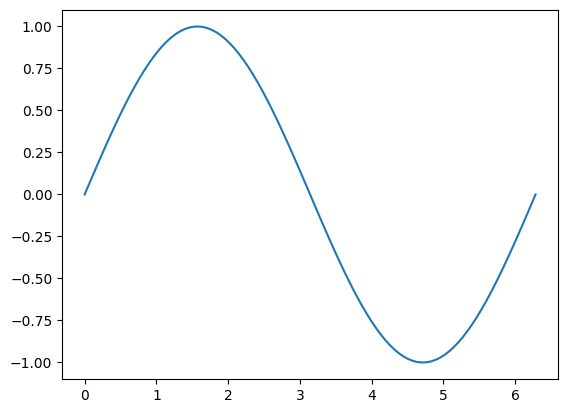

In [19]:
# TODO: xs = np.linspace(0, 2*np.pi, 100), plt.plot(xs, np.sin(xs)), plt.show()
xs = np.linspace(0, 2*np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()


**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

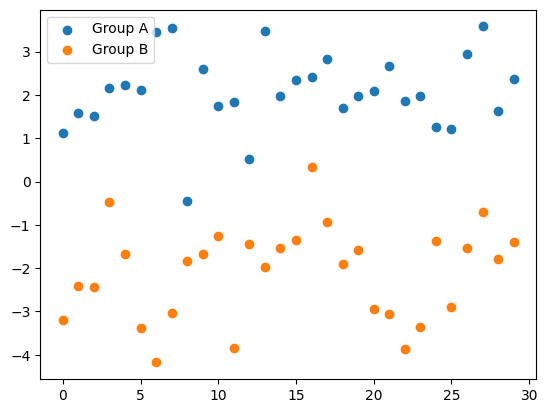

In [20]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),
# додати plt.legend(), plt.show()
x = np.arange(30)

plt.scatter(x, group_a, color='C0', label='Group A')
plt.scatter(x, group_b, color='C1', label='Group B')

plt.legend()
plt.show()



---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [21]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

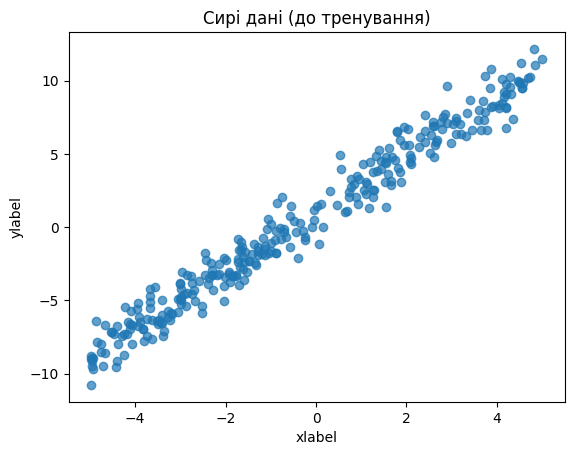

In [22]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок
# "Сирі дані (до тренування)"

plt.scatter(x1, y1, alpha=0.7)
plt.xlabel('xlabel')
plt.ylabel('ylabel')
plt.title('Сирі дані (до тренування)')
plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [23]:
# TODO: перемішати x1/y1 через torch.randperm(TASK1_N), розбити на
# train/val/test у пропорції 70/15/15
# x_train1, y_train1 = ...
# x_val1, y_val1 = ...
# x_test1, y_test1 = ...

indeces = torch.randperm(TASK1_N)

train_size = int(0.7 * TASK1_N)
val_size = int(0.15 * TASK1_N)

train_idx = indeces[:train_size]
val_idx = indeces[train_size : train_size + val_size]
test_idx = indeces[train_size + val_size:]

x_train1, y_train1 = x1[train_idx], y1[train_idx]
x_val1, y_val1 = x1[val_idx], y1[val_idx]
x_test1, y_test1 = x1[test_idx], y1[test_idx]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [24]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


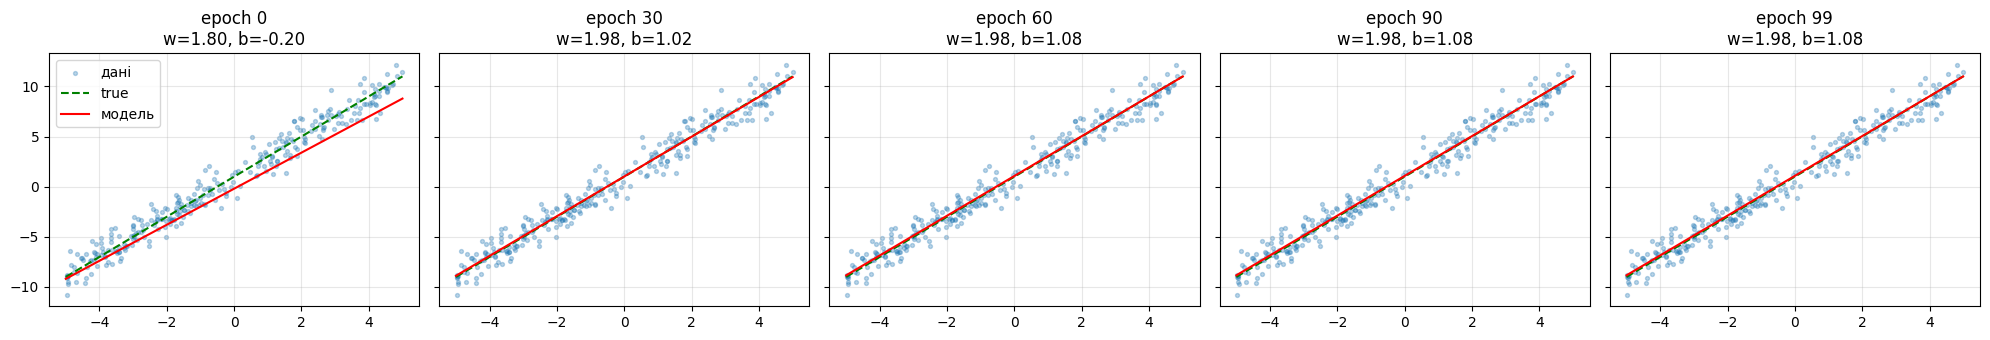

In [25]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

## Вплив екранного часу на рівень втоми очей
Досліджуємо лінійну залежність між кількістю годин, проведених за екраном пристроїв, та суб'єктивним рівнем втоми очей наприкінці дня. X - кількість екранного часу (від 0 до 13 годин), Y - шкала від 0-10, де 0 це гарний стан, а 10 - сильний біль та неможливість сфокосувати зір.

**b = 1.5**: навіть якщо день пройшов повністю без гаджетів, до вечора очі все одно отримують мінімальне природне навантаження (читання, фокусування на далеких об'єктах, вплив кімнатного освітлення).

**w = 0.65**: припускаємо, що кожна година безперервної роботи за монітором додає 0.65 балів до втоми. Таким чином, 8 годин роботи за екраном дадуть помітну втому на рівні 6.7 балів (8 * 0.65 + 1.5). Якщо додати ще пару годин ігор або перегляду відео ввечері (наприклад, 12 годин сумарно), індекс втоми наблизиться до високих 9.3 балів.

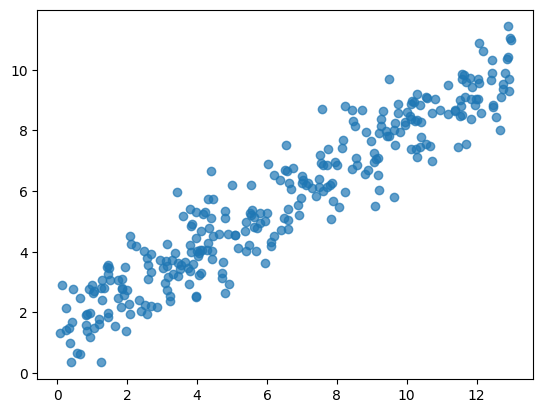

In [26]:
N = 300
w = 0.65
b = 1.5
X = torch.empty(N ,1).uniform_(0, 13)
noise = 0.8 * torch.randn(N, 1)
Y = w * X + b + noise

df = pd.DataFrame({
    'screen_time': X.numpy().flatten(),
    'eye_strain': Y.numpy().flatten()
})

df.to_csv(f'{ARTIFACT_DIR}/dataset.csv', index=False)

plt.scatter(X, Y, alpha=0.7)
plt.show()


In [27]:
def split_tensor(X, Y, test_size=0.2, seed=42):
    g = torch.Generator().manual_seed(seed)
    n = X.shape[0]
    perm = torch.randperm(n, generator=g)
    n_test = int(n * test_size)
    test_idx, train_idx = perm[:n_test], perm[n_test:]
    return X[train_idx], Y[train_idx], X[test_idx], Y[test_idx]

X_train, Y_train, X_test, Y_test = split_tensor(X, Y, test_size=0.2)
print(f"train: {X_train.shape[0]}, test: {X_test.shape[0]}")

train: 240, test: 60


In [28]:
def train_linear_model(X_train, Y_train, epochs=100, lr=0.05, snapshot_every=30, X_mean=None, X_std=None):
    model = torch.nn.Linear(in_features=1, out_features=1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()

    x_line = torch.linspace(0, 13, 100).unsqueeze(1)
    if X_mean is not None and X_std is not None:
        x_line_input = (x_line - X_mean) / X_std
    else:
        x_line_input = x_line

    snapshots = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model(X_train)
        loss = loss_fn(y_pred, Y_train)
        loss.backward()
        optimizer.step()

        if epoch % snapshot_every == 0 or epoch == epochs - 1:
          with torch.no_grad():
            y_line_pred = model(x_line_input)

          snapshots.append((epoch, loss.item(), model.weight.item(), model.bias.item(), y_line_pred))

    return model, snapshots


In [29]:
def evaluate_model(model, X_test, Y_test, loss_fn=None):
    loss_fn = loss_fn or torch.nn.MSELoss()
    model.eval()
    with torch.no_grad():
        test_loss = loss_fn(model(X_test), Y_test).item()
    model.train()
    return test_loss

## З нормалізацією

In [42]:
X_mean, X_std = X_train.mean(), X_train.std()
X_train_norm = (X_train - X_mean) / X_std
X_test_norm = (X_test - X_mean) / X_std

model, snapshots = train_linear_model(X_train_norm, Y_train, epochs=100, lr=0.05, X_mean=X_mean, X_std=X_std)

for epoch, loss, w_hat, b_hat, y_line_pred in snapshots:
    print(f"epoch {epoch:4d}  loss={loss:.6f}  w={w_hat:.4f}  b={b_hat:.4f}")

w_norm = model.weight.item()
b_norm = model.bias.item()
w_hat = w_norm / X_std.item()
b_hat = b_norm - w_norm * X_mean.item() / X_std.item()

test_loss = evaluate_model(model, X_test_norm, Y_test)
print(f"\nTest MSE: {test_loss:.6f}")
print(f"Learned (original scale): w={w_hat:.4f} (true {w}), b={b_hat:.4f} (true {b})")

epoch    0  loss=31.613688  w=0.5853  b=0.9001
epoch   30  loss=0.769948  w=2.3900  b=5.3394
epoch   60  loss=0.714300  w=2.4676  b=5.5276
epoch   90  loss=0.714200  w=2.4710  b=5.5355
epoch   99  loss=0.714200  w=2.4710  b=5.5358

Test MSE: 0.637450
Learned (original scale): w=0.6569 (true 0.65), b=1.4033 (true 1.5)


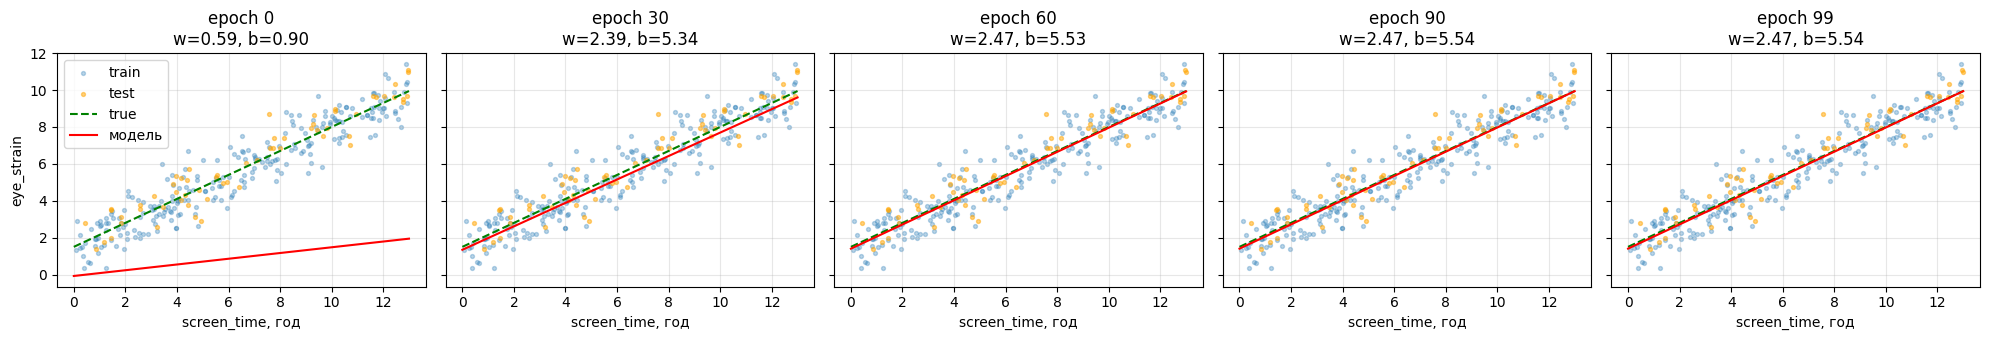

In [43]:
x_line = torch.linspace(0, 13, 100).unsqueeze(1)

with torch.no_grad():
    y_line_true = w * x_line + b

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, loss, w_hat, b_hat, y_line_pred) in zip(axes, snapshots):
  ax.scatter(X_train.numpy(), Y_train.numpy(), s=8, alpha=0.3, label="train")
  ax.scatter(X_test.numpy(), Y_test.numpy(), s=8, alpha=0.5, color="orange", label="test")
  ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
  ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
  ax.set_title(f"epoch {epoch}\nw={w_hat:.2f}, b={b_hat:.2f}")
  ax.set_xlabel("screen_time, год")
  ax.grid(alpha=0.3)

axes[0].set_ylabel("eye_strain")
axes[0].legend()
plt.tight_layout()
plt.show()

## Без нормалізації

In [39]:
model_plain, snapshots_plain = train_linear_model(X_train, Y_train, epochs=100, lr=0.01)

for epoch, loss, w_hat, b_hat, y_line_pred in snapshots_plain:
    print(f"epoch {epoch:4d}  loss={loss:.6f}  w={w_hat:.4f} (true {w})  b={b_hat:.4f} (true {b})")

test_loss_plain = evaluate_model(model_plain, X_test, Y_test)
print(f"\nTest MSE: {test_loss_plain:.6f}")
print(f"Learned: w={model_plain.weight.item():.4f} (true {w}), b={model_plain.bias.item():.4f} (true {b})")

epoch    0  loss=61.741577  w=0.8976 (true 0.65)  b=0.1559 (true 1.5)
epoch   30  loss=1.021812  w=0.7837 (true 0.65)  b=0.3266 (true 1.5)
epoch   60  loss=0.939457  w=0.7654 (true 0.65)  b=0.4819 (true 1.5)
epoch   90  loss=0.879150  w=0.7497 (true 0.65)  b=0.6148 (true 1.5)
epoch   99  loss=0.864429  w=0.7455 (true 0.65)  b=0.6508 (true 1.5)

Test MSE: 0.844682
Learned: w=0.7455 (true 0.65), b=0.6508 (true 1.5)


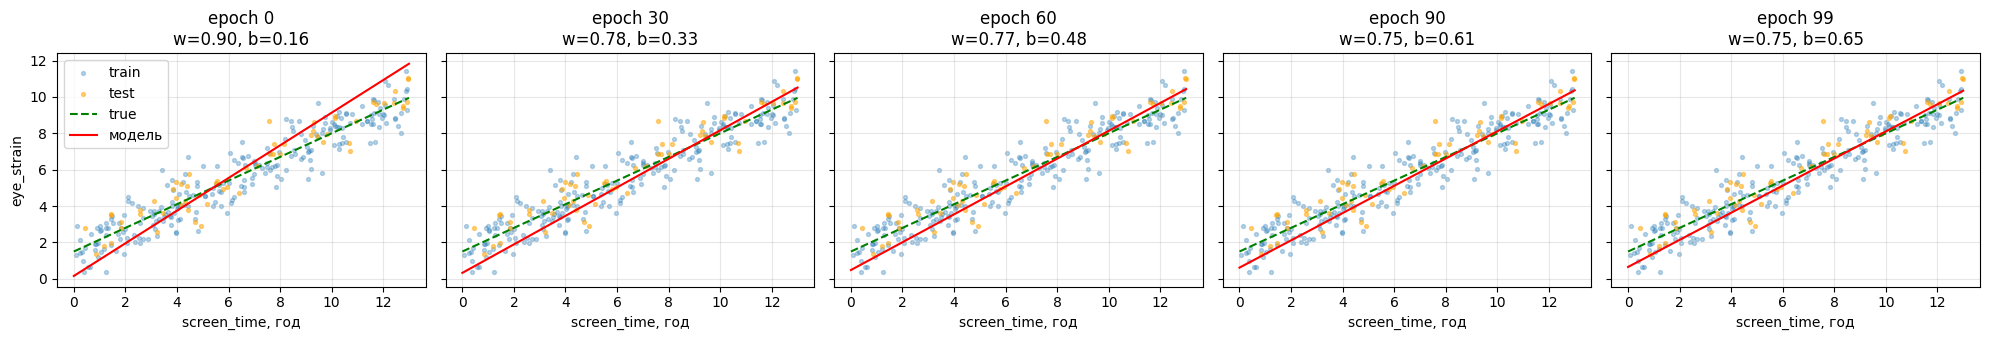

In [40]:
x_line_plain = torch.linspace(0, 13, 100).unsqueeze(1)

with torch.no_grad():
    y_line_true_plain = w * x_line_plain + b

fig_plain, axes_plain = plt.subplots(1, len(snapshots_plain), figsize=(4 * len(snapshots_plain), 3.5), sharey=True)
for ax, (epoch, loss, w_hat, b_hat, y_line_pred) in zip(axes_plain, snapshots_plain):
    ax.scatter(X_train.numpy(), Y_train.numpy(), s=8, alpha=0.3, label="train")
    ax.scatter(X_test.numpy(), Y_test.numpy(), s=8, alpha=0.5, color="orange", label="test")
    ax.plot(x_line_plain.numpy(), y_line_true_plain.numpy(), "g--", label="true")
    ax.plot(x_line_plain.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w_hat:.2f}, b={b_hat:.2f}")
    ax.set_xlabel("screen_time, год")
    ax.grid(alpha=0.3)

axes_plain[0].set_ylabel("eye_strain")
axes_plain[0].legend()
plt.tight_layout()
plt.show()

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [44]:
checkpoint = {
    'model_state_dict': model.state_dict(),
    'X_mean': X_mean,
    'X_std': X_std,
    'w_true': w,
    'b_true': b,
}

torch.save(checkpoint, f'{ARTIFACT_DIR}/model.pt')
print(f"Модель збережено: {ARTIFACT_DIR}/model.pt")



Модель збережено: /content/drive/MyDrive/ai_systems/lab1/model.pt


In [48]:
checkpoint = torch.load(f'{ARTIFACT_DIR}/model.pt')

loaded_model = torch.nn.Linear(in_features=1, out_features=1)
loaded_model.load_state_dict(checkpoint['model_state_dict'])
loaded_model.eval()

X_mean_loaded = checkpoint['X_mean']
X_std_loaded = checkpoint['X_std']

X_new = torch.tensor([[1.0], [5.0], [8.0], [12.0]])
X_new_norm = (X_new - X_mean_loaded) / X_std_loaded

with torch.no_grad():
    y_new_pred = loaded_model(X_new_norm)

for x, y in zip(X_new.flatten().tolist(), y_new_pred.flatten().tolist()):
    print(f"screen_time={x:.1f} год - прогноз eye_strain={y:.2f}")

screen_time=1.0 год - прогноз eye_strain=2.06
screen_time=5.0 год - прогноз eye_strain=4.69
screen_time=8.0 год - прогноз eye_strain=6.66
screen_time=12.0 год - прогноз eye_strain=9.29


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [50]:
import gradio as gr

loaded_model = torch.nn.Linear(in_features=1, out_features=1)
loaded_model.load_state_dict(checkpoint['model_state_dict'])
loaded_model.eval()

X_mean_loaded = checkpoint['X_mean']
X_std_loaded = checkpoint['X_std']

def predict_eye_strain(screen_time):
  x_raw = torch.tensor([[float(screen_time)]])
  x_norm = (x_raw - X_mean_loaded) / X_std_loaded

  with torch.no_grad():
    pred = loaded_model(x_norm)

  return round(pred.item(), 3)

demo = gr.Interface(
    fn=predict_eye_strain,
    inputs=gr.Slider(minimum=0, maximum=13, step=0.5, label="Годин проведено за екраном"),
    outputs=gr.Textbox(label="Прогнозований рівень втоми очей(0-10)"),
    title="Калькулятор втоми очей",
    description="Вкажіть ваш середній екранний час, щоб дізнатися прогнозований рівень втоми наприкінці дня."
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6ed883751f54547013.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```